# v3 — 4 Base Learner Beda Mekanisme + Multi Meta-Learner + Feature Importance

Revisi dari v2. Temuan v2: **XGBoost solo (F1=0.58) ngalahin semua ensemble** — indikasi base learner-nya (XGBoost + CatBoost, dua-duanya boosting) kurang beragam buat di-stack.

Perubahan di v3:
1. **4 base learner, mekanisme beda-beda**: XGBoost & CatBoost (boosting/iterative), Random Forest (bagging tree), Logistic Regression ElasticNet (linear, non-tree).
2. **Cek korelasi antar base learner** sebelum ensembling — biar tau dari awal apa emang ada ruang buat "diversity gain".
3. **4 opsi meta-learner** dirangking adil: Logistic Regression, Random Forest, Gradient Boosting, ANN — semua dilatih & di-threshold pakai skema OOF 5-fold yang sama.
4. **Feature importance / koefisien tiap meta-learner** — nunjukin base model mana yang paling "didengerin".

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score
)

import xgboost as xgb
from catboost import CatBoostClassifier

from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
HORIZON = 7
N_FOLDS = 5


## 2. Rebuild Data & Threshold-Based Weekly Target

In [2]:
data = pd.read_csv('/kaggle/input/datasets/christoperhw/btc-master-iris/bitcoin iris/dataset/master/btc_master_2.csv', index_col=0, parse_dates=True).sort_index()

fear_greed_order = {"Extreme Fear": 0, "Fear": 1, "Neutral": 2, "Greed": 3, "Extreme Greed": 4}
data['value_classification'] = data['value_classification'].map(fear_greed_order)
data['eth_price_is_backfilled'] = data['eth_price_is_backfilled'].astype(int)
data['next_halving_is_projected'] = data['next_halving_is_projected'].astype(int)
data['fomc_rate_changed'] = data['fomc_rate_changed'].astype(int)

print("Shape:", data.shape, "| Range:", data.index.min().date(), "->", data.index.max().date())


Shape: (3124, 73) | Range: 2018-02-01 -> 2026-08-21


In [3]:
def safe_divide(numerator, denominator):
    denominator = pd.Series(denominator, index=data.index, dtype=float)
    return pd.Series(numerator, index=data.index, dtype=float) / denominator.replace(0, np.nan)

def calculate_rsi(close, window):
    change = close.diff()
    gain = change.clip(lower=0).ewm(alpha=1/window, adjust=False, min_periods=window).mean()
    loss = (-change.clip(upper=0)).ewm(alpha=1/window, adjust=False, min_periods=window).mean()
    rs = safe_divide(gain, loss)
    return 100 - (100 / (1 + rs))

def calculate_true_range(high, low, close):
    return pd.concat([
        high - low, (high - close.shift(1)).abs(), (low - close.shift(1)).abs()
    ], axis=1).max(axis=1)

close = data['btc_close'].astype(float)
high = data['btc_high'].astype(float)
low = data['btc_low'].astype(float)
open_ = data['btc_open'].astype(float)
volume = data['btc_volume'].astype(float)
log_close = np.log(close.where(close > 0))
return_1d = log_close.diff()
true_range = calculate_true_range(high, low, close)

engineered = pd.DataFrame(index=data.index)

for window in [3, 7, 14, 30, 60, 90]:
    engineered[f'log_return_{window}d'] = log_close.diff(window)
    engineered[f'volatility_{window}d'] = return_1d.rolling(window, min_periods=window).std()
    rolling_high = close.rolling(window, min_periods=window).max()
    rolling_low = close.rolling(window, min_periods=window).min()
    engineered[f'drawdown_{window}d'] = safe_divide(close, rolling_high) - 1
    engineered[f'channel_pos_{window}d'] = safe_divide(close - rolling_low, rolling_high - rolling_low)

for window in [5, 8, 13, 21, 50, 100, 200]:
    ema = close.ewm(span=window, adjust=False, min_periods=window).mean()
    engineered[f'ema_distance_{window}'] = safe_divide(close, ema) - 1
    engineered[f'ema_slope_{window}'] = ema.pct_change()

for window in [7, 14, 21, 28]:
    rsi = calculate_rsi(close, window)
    engineered[f'rsi_{window}'] = rsi
    engineered[f'rsi_distance50_{window}'] = rsi - 50

for fast, slow, sig in [(12, 26, 9), (5, 35, 5)]:
    macd = close.ewm(span=fast, adjust=False).mean() - close.ewm(span=slow, adjust=False).mean()
    signal = macd.ewm(span=sig, adjust=False).mean()
    engineered[f'macd_hist_{fast}_{slow}_{sig}'] = safe_divide(macd - signal, close)

for window in [14, 20, 30]:
    mid = close.rolling(window, min_periods=window).mean()
    std = close.rolling(window, min_periods=window).std()
    upper, lower = mid + 2*std, mid - 2*std
    engineered[f'bb_percent_b_{window}'] = safe_divide(close - lower, upper - lower)
    engineered[f'bb_width_{window}'] = safe_divide(upper - lower, mid)

for window in [7, 14, 21]:
    atr = true_range.ewm(alpha=1/window, adjust=False, min_periods=window).mean()
    engineered[f'atr_norm_{window}'] = safe_divide(atr, close)

candle_range = high - low
engineered['candle_range_pct'] = safe_divide(candle_range, close)
engineered['candle_body_pct'] = safe_divide(close - open_, open_)
engineered['candle_close_location'] = safe_divide(close - low, candle_range)
engineered['candle_gap_pct'] = safe_divide(open_, close.shift(1)) - 1

non_technical_cols = [c for c in data.columns if c not in
    ['btc_open', 'btc_high', 'btc_low', 'btc_close', 'btc_volume', 'label', 'market_price_usd']
    and c not in engineered.columns
    and data[c].dtype != 'object']

print(f"Total fitur teknikal + non-teknikal: {engineered.shape[1] + len(non_technical_cols)}")


Total fitur teknikal + non-teknikal: 127


In [4]:
future_return_7d = np.log(data['btc_close'].shift(-HORIZON) / data['btc_close'])
weekly_vol = return_1d.rolling(HORIZON, min_periods=HORIZON).std() * np.sqrt(HORIZON)

threshold_label = pd.Series(np.nan, index=data.index)
significant_up = future_return_7d > 0.5 * weekly_vol
significant_down = future_return_7d < -0.5 * weekly_vol
threshold_label[significant_up] = 1
threshold_label[significant_down] = 0

full_features = engineered.join(data[non_technical_cols], how='left')
full_features['target'] = threshold_label
full_features_clean = full_features.dropna().sort_index()

print(f"Total baris setelah threshold labeling + dropna: {full_features_clean.shape[0]}")
print(full_features_clean['target'].value_counts())


Total baris setelah threshold labeling + dropna: 1692
target
1.0    921
0.0    771
Name: count, dtype: int64


## 3. Split Train / Validation / Test (Time-Ordered, Purged)

In [5]:
n = len(full_features_clean)
train_end = int(n * 0.6)
val_start = train_end + HORIZON
val_end = train_end + int(n * 0.2)
test_start = val_end + HORIZON

X_all = full_features_clean.drop(columns=['target'])
y_all = full_features_clean['target']

X_train, y_train = X_all.iloc[:train_end], y_all.iloc[:train_end]
X_val, y_val = X_all.iloc[val_start:val_end], y_all.iloc[val_start:val_end]
X_test, y_test = X_all.iloc[test_start:], y_all.iloc[test_start:]

for name, X_ in [('Train', X_train), ('Validation', X_val), ('Test', X_test)]:
    print(f"{name}: {X_.shape[0]} obs | {X_.index.min().date()} -> {X_.index.max().date()}")

pos_rate = y_train.mean()
scale_pos_weight = (1 - pos_rate) / pos_rate
print(f"\nTrain pos rate: {pos_rate:.3f} | scale_pos_weight: {scale_pos_weight:.3f}")


Train: 1015 obs | 2018-08-20 -> 2023-05-29
Validation: 331 obs | 2023-06-15 -> 2025-01-14
Test: 332 obs | 2025-01-30 -> 2026-08-09

Train pos rate: 0.547 | scale_pos_weight: 0.829


## 4. Purged CV Splitter (Dipakai di Train utk Tuning, dan di Validation utk OOF Meta-Learner)

In [6]:
def purged_cv_splits(n_samples, n_splits=N_FOLDS, horizon=HORIZON, min_train_frac=0.5):
    min_train_size = int(n_samples * min_train_frac)
    remaining = n_samples - min_train_size
    fold_size = remaining // n_splits

    splits = []
    for i in range(n_splits):
        val_s = min_train_size + i * fold_size
        val_e = min_train_size + (i + 1) * fold_size if i < n_splits - 1 else n_samples
        train_e = val_s - horizon
        if train_e <= 0 or val_e <= val_s:
            continue
        splits.append((np.arange(0, train_e), np.arange(val_s, val_e)))
    return splits

inner_cv = purged_cv_splits(len(X_train))
print(f"{len(inner_cv)} inner fold (Train) buat hyperparameter tuning")


5 inner fold (Train) buat hyperparameter tuning


## 5. Hyperparameter Tuning — 4 Base Learner, Mekanisme Beda-Beda

- **XGBoost, CatBoost** — boosting/iterative (persis v2)
- **Random Forest** — bagging tree, trees independen + voting (bukan koreksi error berurutan kayak boosting)
- **Logistic Regression (ElasticNet)** — linear, sama sekali bukan tree. Perlu `StandardScaler` (dibungkus `Pipeline` biar scaler cuma "belajar" dari fold training, nggak bocor ke fold validasi).

In [7]:
xgb_param_grid = {
    'n_estimators': [200, 400], 'max_depth': [3, 4, 5],
    'learning_rate': [0.03, 0.05, 0.08], 'reg_lambda': [1.0, 5.0],
}
xgb_base = xgb.XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
                              random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1)
xgb_grid = GridSearchCV(xgb_base, xgb_param_grid, scoring='roc_auc', cv=inner_cv, n_jobs=-1).fit(X_train, y_train)
print("XGBoost best:", xgb_grid.best_params_, "| AUC:", round(xgb_grid.best_score_, 4))


XGBoost best: {'learning_rate': 0.08, 'max_depth': 5, 'n_estimators': 200, 'reg_lambda': 5.0} | AUC: 0.6419


In [8]:
cat_param_grid = {
    'iterations': [200, 400], 'depth': [3, 4, 5],
    'learning_rate': [0.03, 0.05, 0.08], 'l2_leaf_reg': [3.0, 8.0],
}
cat_base = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, auto_class_weights='Balanced')
cat_grid = GridSearchCV(cat_base, cat_param_grid, scoring='roc_auc', cv=inner_cv, n_jobs=-1).fit(X_train, y_train)
cat_best = cat_grid.best_estimator_
print("CatBoost best:", cat_grid.best_params_, "| AUC:", round(cat_grid.best_score_, 4))


CatBoost best: {'depth': 3, 'iterations': 200, 'l2_leaf_reg': 3.0, 'learning_rate': 0.05} | AUC: 0.6434


In [9]:
rf_param_grid = {
    'n_estimators': [300, 500], 'max_depth': [4, 6, 8],
    'min_samples_leaf': [10, 30],
}
rf_base = RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
rf_grid = GridSearchCV(rf_base, rf_param_grid, scoring='roc_auc', cv=inner_cv, n_jobs=-1).fit(X_train, y_train)
rf_best = rf_grid.best_estimator_
print("Random Forest best:", rf_grid.best_params_, "| AUC:", round(rf_grid.best_score_, 4))


Random Forest best: {'max_depth': 8, 'min_samples_leaf': 10, 'n_estimators': 300} | AUC: 0.5948


In [10]:
logreg_base_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000,
                                class_weight='balanced', random_state=RANDOM_STATE)),
])
logreg_param_grid = {'clf__C': [0.01, 0.1, 1.0], 'clf__l1_ratio': [0.2, 0.5, 0.8]}
logreg_grid = GridSearchCV(logreg_base_pipe, logreg_param_grid, scoring='roc_auc', cv=inner_cv, n_jobs=-1).fit(X_train, y_train)
logreg_best = logreg_grid.best_estimator_
print("Logistic Regression best:", logreg_grid.best_params_, "| AUC:", round(logreg_grid.best_score_, 4))


Logistic Regression best: {'clf__C': 0.1, 'clf__l1_ratio': 0.2} | AUC: 0.6527


## 6. Refit XGBoost dengan Learning-Rate Scheduler (Cosine Decay)

In [11]:
best_lr = xgb_grid.best_params_['learning_rate']
n_rounds = xgb_grid.best_params_['n_estimators']

def cosine_lr_schedule(round_idx):
    progress = round_idx / max(n_rounds - 1, 1)
    return best_lr * (0.1 + 0.9 * (1 + np.cos(np.pi * progress)) / 2)

xgb_best = xgb.XGBClassifier(**xgb_grid.best_params_, subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE,
                              eval_metric='logloss', n_jobs=-1, callbacks=[xgb.callback.LearningRateScheduler(cosine_lr_schedule)])
xgb_best.fit(X_train, y_train)
print("XGBoost final (scheduler LR) siap.")


XGBoost final (scheduler LR) siap.


## 7. Evaluasi 4 Base Learner + Cek Korelasi Probabilitas

Ini diagnostik paling penting sebelum ensembling: kalau probabilitas antar model korelasinya tinggi (>0.9), ensemble apapun nggak akan banyak beda dari model terbaiknya sendirian.

In [12]:
def evaluate(y_true, y_pred, y_proba):
    return {
        'accuracy': accuracy_score(y_true, y_pred), 'f1_macro': f1_score(y_true, y_pred, average='macro'),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'mcc': matthews_corrcoef(y_true, y_pred), 'auc': roc_auc_score(y_true, y_proba),
    }

def find_best_threshold(y_true, proba, thresholds=np.arange(0.05, 0.96, 0.01)):
    scores = [f1_score(y_true, (proba >= th).astype(int), average='macro') for th in thresholds]
    best_i = int(np.argmax(scores))
    return thresholds[best_i], scores[best_i]

base_models = {'XGBoost': xgb_best, 'CatBoost': cat_best, 'RandomForest': rf_best, 'LogReg': logreg_best}
base_proba_val, base_proba_test, base_th = {}, {}, {}

for name, model in base_models.items():
    base_proba_val[name] = model.predict_proba(X_val)[:, 1]
    base_proba_test[name] = model.predict_proba(X_test)[:, 1]
    th, score = find_best_threshold(y_val, base_proba_val[name])
    base_th[name] = th
    print(f"{name:12s} best threshold = {th:.2f} | F1 macro val = {score:.4f}")

proba_val_df = pd.DataFrame(base_proba_val)
print("\nKorelasi probabilitas antar base learner (Validation):")
print(proba_val_df.corr().round(3))


XGBoost      best threshold = 0.18 | F1 macro val = 0.5749
CatBoost     best threshold = 0.21 | F1 macro val = 0.5737
RandomForest best threshold = 0.35 | F1 macro val = 0.5372
LogReg       best threshold = 0.06 | F1 macro val = 0.6066

Korelasi probabilitas antar base learner (Validation):
              XGBoost  CatBoost  RandomForest  LogReg
XGBoost         1.000     0.881         0.770   0.631
CatBoost        0.881     1.000         0.782   0.707
RandomForest    0.770     0.782         1.000   0.440
LogReg          0.631     0.707         0.440   1.000


## 8. Meta-Features (4 Kolom Probabilitas) + Average Ensemble Baseline

In [13]:
meta_cols = list(base_models.keys())
meta_X_val = proba_val_df[meta_cols].values
meta_X_test = pd.DataFrame(base_proba_test)[meta_cols].values

avg_proba_val = meta_X_val.mean(axis=1)
avg_proba_test = meta_X_test.mean(axis=1)
avg_th, avg_th_score = find_best_threshold(y_val, avg_proba_val)
print(f"Average Ensemble (4 model) best threshold = {avg_th:.2f} | F1 macro val = {avg_th_score:.4f}")


Average Ensemble (4 model) best threshold = 0.22 | F1 macro val = 0.5909


## 9. 4 Opsi Meta-Learner, Dirangking Adil (Sama-Sama Pakai OOF 5-Fold)

Semua meta-learner dilatih & dievaluasi threshold-nya dengan cara yang sama: 5-fold purged CV *di dalam Validation*, threshold dicari dari prediksi out-of-fold, baru versi final di-retrain di seluruh Validation buat dipakai ke Test. Ini bikin perbandingan antar meta-learner apple-to-apple (di v2 cuma ANN yang dapet perlakuan ini).

In [14]:
def get_meta_learners():
    return {
        'LogReg': LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE),
        'RandomForest': RandomForestClassifier(n_estimators=200, max_depth=3, min_samples_leaf=10,
                                                class_weight='balanced', random_state=RANDOM_STATE),
        'GradientBoosting': GradientBoostingClassifier(n_estimators=100, max_depth=2,
                                                         learning_rate=0.05, random_state=RANDOM_STATE),
    }

def build_meta_ann(n_features):
    keras.utils.set_random_seed(RANDOM_STATE)
    m = keras.Sequential([
        layers.Input(shape=(n_features,)), layers.Dense(8, activation='relu'),
        layers.Dense(4, activation='relu'), layers.Dense(1, activation='sigmoid'),
    ])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy')
    return m

def fit_meta_ann(model, X, y):
    callbacks = [
        keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.5, patience=8, min_lr=1e-5),
        keras.callbacks.EarlyStopping(monitor='loss', patience=15, restore_best_weights=True),
    ]
    model.fit(X, y, epochs=150, batch_size=16, verbose=0, callbacks=callbacks)
    return model

def has_two_classes(y):
    return len(np.unique(y)) >= 2

meta_folds = purged_cv_splits(len(meta_X_val), n_splits=N_FOLDS, min_train_frac=0.5)
print(f"{len(meta_folds)} fold OOF di dalam Validation\n")

meta_oof = {name: np.full(len(meta_X_val), np.nan) for name in list(get_meta_learners().keys()) + ['ANN']}
skipped_folds = []

for fold_i, (fold_train_idx, fold_val_idx) in enumerate(meta_folds):
    y_fold_train = y_val.values[fold_train_idx]
    if not has_two_classes(y_fold_train):
        skipped_folds.append(fold_i)
        continue
    for name, clf in get_meta_learners().items():
        clf.fit(meta_X_val[fold_train_idx], y_fold_train)
        meta_oof[name][fold_val_idx] = clf.predict_proba(meta_X_val[fold_val_idx])[:, 1]
    ann_fold = build_meta_ann(meta_X_val.shape[1])
    fit_meta_ann(ann_fold, meta_X_val[fold_train_idx], y_fold_train)
    meta_oof['ANN'][fold_val_idx] = ann_fold.predict(meta_X_val[fold_val_idx], verbose=0).ravel()

if skipped_folds:
    print(f"Fold di-skip (training slice cuma 1 kelas): {skipped_folds}")

has_oof = ~np.isnan(meta_oof['LogReg'])
print(f"Baris dengan prediksi OOF: {has_oof.sum()} dari {len(meta_X_val)}\n")

meta_th, meta_ranking = {}, []
for name, oof_proba in meta_oof.items():
    th, score = find_best_threshold(y_val.values[has_oof], oof_proba[has_oof])
    meta_th[name] = th
    meta_ranking.append({'meta_learner': name, 'oof_threshold': th, 'oof_f1_macro': score})

meta_ranking_df = pd.DataFrame(meta_ranking).sort_values('oof_f1_macro', ascending=False)
print("Ranking meta-learner berdasarkan OOF F1 macro (di Validation, sebelum lihat Test):")
print(meta_ranking_df.to_string(index=False))


5 fold OOF di dalam Validation



I0000 00:00:1788419129.677855      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13348 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788419129.681193      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1788419133.571646    1523 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Baris dengan prediksi OOF: 166 dari 331

Ranking meta-learner berdasarkan OOF F1 macro (di Validation, sebelum lihat Test):
    meta_learner  oof_threshold  oof_f1_macro
             ANN           0.53      0.576202
GradientBoosting           0.42      0.532232
    RandomForest           0.35      0.527456
          LogReg           0.48      0.502485


## 10. Retrain Final Tiap Meta-Learner di Seluruh Validation, Prediksi ke Test

In [15]:
meta_final = get_meta_learners()
meta_proba_test = {}

for name, clf in meta_final.items():
    clf.fit(meta_X_val, y_val.values)
    meta_proba_test[name] = clf.predict_proba(meta_X_test)[:, 1]

ann_final = build_meta_ann(meta_X_val.shape[1])
fit_meta_ann(ann_final, meta_X_val, y_val.values)
meta_proba_test['ANN'] = ann_final.predict(meta_X_test, verbose=0).ravel()

print("Semua meta-learner final sudah di-retrain & prediksi ke Test.")


Semua meta-learner final sudah di-retrain & prediksi ke Test.


## 11. Feature Importance / Koefisien Tiap Meta-Learner

Nunjukin base model mana yang paling "didengerin" di keputusan akhir. Kalau satu kolom dominan banget (>70-80%), itu artinya ensemble-nya secara efektif cuma nyamar jadi model itu doang.

Kontribusi tiap base learner di masing-masing meta-learner:
              LogReg (coef)  RandomForest (importance)  \
XGBoost               0.703                      0.220   
CatBoost              0.209                      0.292   
RandomForest         -0.370                      0.166   
LogReg                0.986                      0.322   

              GradientBoosting (importance)  
XGBoost                               0.204  
CatBoost                              0.265  
RandomForest                          0.203  
LogReg                                0.327  


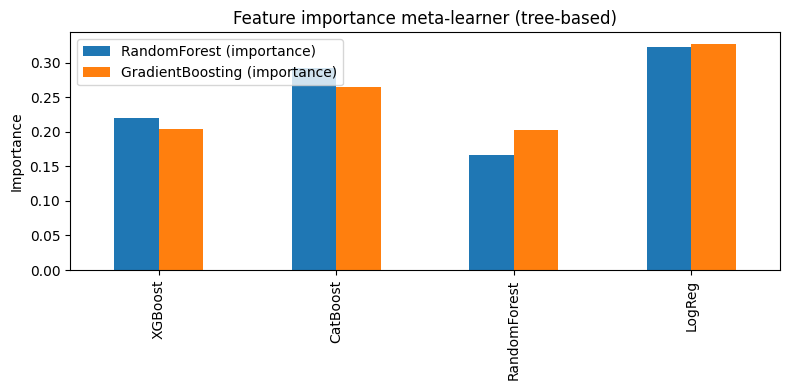

In [16]:
importance_table = pd.DataFrame(index=meta_cols)
importance_table['LogReg (coef)'] = meta_final['LogReg'].coef_[0]
importance_table['RandomForest (importance)'] = meta_final['RandomForest'].feature_importances_
importance_table['GradientBoosting (importance)'] = meta_final['GradientBoosting'].feature_importances_

print("Kontribusi tiap base learner di masing-masing meta-learner:")
print(importance_table.round(3))

importance_table[['RandomForest (importance)', 'GradientBoosting (importance)']].plot(
    kind='bar', figsize=(8, 4), title='Feature importance meta-learner (tree-based)')
plt.ylabel('Importance'); plt.tight_layout(); plt.show()


## 12. Perbandingan Akhir — Test Set (Base Learner + Average + 4 Meta-Learner)

In [17]:
final_results = {}
for name, model in base_models.items():
    final_results[f'Base - {name}'] = evaluate(y_test, (pd.DataFrame(base_proba_test)[name] >= base_th[name]).astype(int),
                                                pd.DataFrame(base_proba_test)[name])
final_results['Ensemble - Average (4 model)'] = evaluate(y_test, (avg_proba_test >= avg_th).astype(int), avg_proba_test)
for name, proba in meta_proba_test.items():
    final_results[f'Meta - {name}'] = evaluate(y_test, (proba >= meta_th[name]).astype(int), proba)

final_results_df = pd.DataFrame(final_results).T.round(4).sort_values('f1_macro', ascending=False)
print(final_results_df)
print(f"\nBest overall (F1 macro): {final_results_df.index[0]}")


                              accuracy  f1_macro  balanced_accuracy     mcc  \
Meta - GradientBoosting         0.5994    0.5881             0.6075  0.2315   
Base - XGBoost                  0.5843    0.5799             0.5897  0.1850   
Ensemble - Average (4 model)    0.5783    0.5776             0.5811  0.1634   
Meta - LogReg                   0.5813    0.5742             0.5769  0.1574   
Meta - ANN                      0.5723    0.5536             0.5820  0.1836   
Meta - RandomForest             0.5904    0.5530             0.6036  0.2640   
Base - LogReg                   0.5904    0.5398             0.5774  0.1973   
Base - CatBoost                 0.5181    0.4943             0.5282  0.0640   
Base - RandomForest             0.5090    0.4919             0.5022  0.0046   

                                 auc  
Meta - GradientBoosting       0.6449  
Base - XGBoost                0.5920  
Ensemble - Average (4 model)  0.5833  
Meta - LogReg                 0.6204  
Meta - ANN    

## Catatan

- Ranking meta-learner di Section 9 dibuat dari OOF (sebelum ngintip Test) — jadi kalau ranking OOF-nya beda sama ranking Test di Section 12, itu tanda meta-learner-nya nggak stabil/overfit ke Validation, bukan tanda salah pilih model.
- Kalau di Section 7 korelasi antar base learner ternyata semuanya tinggi (>0.85-0.9), jangan kaget kalau base learner terbaik sendirian masih menang lawan semua ensemble — itu bukan bug di kode, itu emang batasnya diversity di data ini.
- Random Forest & Logistic Regression di sini pakai fitur mentah yang sama kayak XGBoost/CatBoost (bukan fitur yang beda) — kalau korelasi masih tinggi meski mekanismenya beda, kemungkinan sinyal di semua fitur ini emang cuma nangkep 1 pola dominan yang sama, bukan banyak pola independen.